# Grid-search based co-design optimization

```
rsync -avm --include='*/' --include='*.sql*' --exclude='*' jhummel@snellius.surf.nl:/home/jhummel/Tower-clearance-co-design/data/co-design/ ./data/co-design/ --dry-run
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.interpolate import griddata
from weis.visualization.utils import load_OMsql, load_OMsql_multi

plt.style.use("journal.mplstyle")

# %matplotlib widget

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.DeprecationWarning: /home/jhummel/miniforge3/envs/tip_clearance/lib/python3.13/site-packages/pkg_resources/__init__.py:3146
Deprecated call to `pkg_resources.declare_namespace('sphinxcontrib')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-packagesDeprecationWarning: /home/jhummel/miniforge3/envs/tip_clearance/lib/python3.13/site-packages/jsonmerge/__init__.py:27
Accessing Draft4Validator.resolver is deprecated as of v4.18.0, in favor of the https://github.com/python-jsonschema/referencing library, which provides more compliant referencing behavior as well as more flexible APIs for customization.PendingDepre

In [5]:
logs_to_load = {
    "Baseline": "../../../data/co-design/baseline_28823409/baseline.sql",
}

# Load all datasets.
all_data_dicts = {}
for log_name, log_fmt in logs_to_load.items():
    all_data_dicts[log_name] = load_OMsql(log_fmt)
    print(f"Loaded {log_name}: {all_data_dicts[log_name].keys()}")

Loaded Baseline: dict_keys(['aeroelastic.platform_displacement', 'aeroelastic.hub_system_cm', 'aeroelastic.platform_elem_rho', 'aeroelastic.platform_elem_E', 'aeroelastic.platform_elem_G', 'aeroelastic.platform_total_center_of_mass', 'aeroelastic.platform_mass', 'aeroelastic.platform_I_total', 'aeroelastic.beta_wave', 'aeroelastic.gamma_f', 'aeroelastic.gamma_m', 'aeroelastic.E', 'aeroelastic.twr2shaft', 'aeroelastic.Xt', 'aeroelastic.Xc', 'aeroelastic.m', 'aeroelastic.definition_layer', 'aeroelastic.sc_ss_mats', 'aeroelastic.sc_ps_mats', 'aeroelastic.te_ss_mats', 'aeroelastic.te_ps_mats', 'aeroelastic.monopile_wohlerexp', 'aeroelastic.monopile_wohlerA', 'aeroelastic.monopile_ultstress', 'aeroelastic.pitch_axis', 'aeroelastic.monopile_axial_load2stress', 'aeroelastic.monopile_shear_load2stress', 'aeroelastic.transition_node', 'aeroelastic.platform_nodes', 'aeroelastic.platform_elem_n1', 'aeroelastic.platform_elem_n2', 'aeroelastic.platform_elem_D', 'aeroelastic.platform_elem_t', 'aeroe

In [6]:
# Let's define how we load, scale, and label the data, then make a dataframe.
all_outputs = {
    # Did the run have a failure.
    "openfast_failed": {
        "key": "aeroelastic.openfast_failed",
        "scaling": lambda x: x[0],
        "label": "Openfast failed",
    },
    # ROSCO variables.
    "TCIPC_MaxTipDeflection": {
        "key": "tune_rosco_ivc.TCIPC_MaxTipDeflection",
        "scaling": lambda x: x[0],
        "label": "TCIPC deflection reference (m)",
    },
    "ps_percent": {
        "key": "tune_rosco_ivc.ps_percent",
        "scaling": lambda x: x[0],
        "label": "Peak shaving (-)",
    },
    "max_thrust_percent": {
        "key": "tune_rosco_ivc.ps_percent",
        "scaling": lambda x: 100 * x[0],
        "label": "Max thrust (%)",
    },
    "TCIPC_nHarmonics": {
        "key": "tune_rosco_ivc.TCIPC_nHarmonics",
        "scaling": lambda x: x[0],
        "label": "Number of harmonics",
    },
    "TCIPC_ZeroYawDeflection": {
        "key": "tune_rosco_ivc.TCIPC_ZeroYawDeflection",
        "scaling": lambda x: x[0],
        "label": "Zero yaw deflection",
    },
    "TCIPC_MaxPitchAmplitude": {
        "key": "tune_rosco_ivc.TCIPC_MaxPitchAmplitude",
        "scaling": lambda x: np.round(np.rad2deg(x[0]), 1),
        "label": "TCIPC max pitch amplitude (deg)",
    },
    # Design variables
    "cone": {
        "key": "hub.cone",
        "scaling": lambda x: np.rad2deg(x[0]),
        "label": "Cone angle (deg)",
    },
    "tilt": {
        "key": "nacelle.uptilt",
        "scaling": lambda x: np.rad2deg(x[0]),
        "label": "Tilt angle (deg)",
    },
    "overhang": {
        "key": "nacelle.overhang",
        "scaling": lambda x: x[0],
        "label": "Overhang (m)",
    },
    # Objective.
    "aep": {
        "key": "aeroelastic.AEP",
        "scaling": lambda x: 1e-6 * x[0],
        "label": "AEP (GWh)",
    },
    # Constraints.
    "max_eff_TipDxc_towerPassing": {
        "key": "aeroelastic.max_eff_TipDxc_towerPassing",
        "scaling": lambda x: x[0],
        "label": "max_eff_TipDxc_towerPassing",
    },
    "tower_clearance": {
        "key": "aeroelastic.minimum_tower_clearance",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    "eff_tower_clearance": {
        "key": "aeroelastic.minimum_eff_tower_clearance",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    "eff_tower_clearance_DLC": {
        "key": "aeroelastic.minimum_eff_tower_clearance_DLC",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    "eff_tower_clearance_URef": {
        "key": "aeroelastic.minimum_eff_tower_clearance_URef",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    # Structural loads.
    "max_eff_TwrBsMyt": {
        "key": "aeroelastic.max_eff_TwrBsMyt",
        "scaling": lambda x: x[0] / 1000,
        "label": "Tower ultimate (MNm)",
    },
    "max_eff_TwrBsMyt_DLC": {
        "key": "aeroelastic.max_eff_TwrBsMyt_DLC",
        "scaling": lambda x: str(x[0]),
        "label": "Max tower base Myt DLC (-)",
    },
    "max_eff_TwrBsMyt_URef": {
        "key": "aeroelastic.max_eff_TwrBsMyt_URef",
        "scaling": lambda x: x[0],
        "label": "Max tower base Myt U (m/s)",
    },
    "DEL_TwrBsMyt": {
        "key": "aeroelastic.DEL_TwrBsMyt",
        "scaling": lambda x: x[0] / 1000,
        "label": "Tower fatigue (MNm)",
    },
    "max_eff_RootMyb": {
        "key": "aeroelastic.max_eff_RootMyb",
        "scaling": lambda x: x[0] / 1000,
        "label": "Blade ultimate (MNm)",
    },
    "max_eff_RootMyb_DLC": {
        "key": "aeroelastic.max_eff_RootMyb_DLC",
        "scaling": lambda x: str(x[0]),
        "label": "Max root Myb DLC (-)",
    },
    "max_eff_RootMyb_URef": {
        "key": "aeroelastic.max_eff_RootMyb_URef",
        "scaling": lambda x: x[0],
        "label": "Max root Myb U (m/s)",
    },
    "DEL_RootMyb": {
        "key": "aeroelastic.DEL_RootMyb",
        "scaling": lambda x: x[0] / 1000,
        "label": "Blade fatigue (MNm)",
    },
    # Control activity.
    "max_pitch_rate_sim": {
        "key": "aeroelastic.max_pitch_rate_sim",
        "scaling": lambda x: x[0],
        "label": "Max pitch rate (deg/s)",
    },
    "max_pitch_rate_sim_DLC": {
        "key": "aeroelastic.max_pitch_rate_sim_DLC",
        "scaling": lambda x: str(x[0]),
        "label": "Max pitch rate DLC (-)",
    },
    "max_pitch_rate_sim_URef": {
        "key": "aeroelastic.max_pitch_rate_sim_U",
        "scaling": lambda x: x[0],
        "label": "Max pitch rate U (m/s)",
    },
    "avg_pitch_travel": {
        "key": "aeroelastic.avg_pitch_travel",
        "scaling": lambda x: x[0],
        "label": "Avg pitch travel (deg)",
    },
}

# Build dataframe from mapping for each log.
labels = {short: info["label"] for short, info in all_outputs.items()}
all_dfs = []

for log_name, data_dict in all_data_dicts.items():
    df_dict = {}
    for short_label, info in all_outputs.items():
        data = data_dict[info["key"]]
        scaled_data = list(map(info["scaling"], data))
        df_dict[short_label] = scaled_data

    df_temp = pd.DataFrame(df_dict)
    df_temp["log_name"] = log_name
    all_dfs.append(df_temp)

# Combine all dataframes.
df = pd.concat(all_dfs, ignore_index=True)
print(f"Combined dataframe shape: {df.shape}")
with pd.option_context(
    "display.max_rows",
    20,
    "display.max_columns",
    None,
    "display.precision",
    3,
):
    display(df)

Combined dataframe shape: (125, 29)


,openfast_failed,TCIPC_MaxTipDeflection,ps_percent,max_thrust_percent,TCIPC_nHarmonics,TCIPC_ZeroYawDeflection,TCIPC_MaxPitchAmplitude,cone,tilt,overhang,aep,max_eff_TipDxc_towerPassing,tower_clearance,eff_tower_clearance,eff_tower_clearance_DLC,eff_tower_clearance_URef,max_eff_TwrBsMyt,max_eff_TwrBsMyt_DLC,max_eff_TwrBsMyt_URef,DEL_TwrBsMyt,max_eff_RootMyb,max_eff_RootMyb_DLC,max_eff_RootMyb_URef,DEL_RootMyb,max_pitch_rate_sim,max_pitch_rate_sim_DLC,max_pitch_rate_sim_URef,avg_pitch_travel,log_name
0,2.0,0.0,0.6,60.0,1.0,0.0,0.0,0.0,0.0,12.031,53.027,9.078,0.000,0.000,1.1,9.00,364.245,1.4,10.59,34.165,103.471,1.4,10.59,15.420,0.071,1.4,10.59,0.057,Baseline
1,0.0,0.0,0.6,60.0,1.0,0.0,0.0,5.0,0.0,12.031,76.784,16.224,5.542,6.327,1.4,10.59,370.123,1.4,10.59,48.083,105.162,1.4,10.59,21.644,0.108,1.3,10.59,0.066,Baseline
2,0.0,0.0,0.6,60.0,1.0,0.0,0.0,10.0,0.0,12.031,77.608,18.785,13.463,14.458,1.4,10.59,387.072,1.4,10.59,48.293,108.950,1.4,10.59,22.387,0.115,1.3,10.59,0.068,Baseline
3,0.0,0.0,0.6,60.0,1.0,0.0,0.0,15.0,0.0,12.031,80.431,23.885,19.932,20.388,1.4,10.59,405.364,1.4,10.59,49.710,115.138,1.4,10.59,24.525,0.107,1.3,10.59,0.077,Baseline
4,0.0,0.0,0.6,60.0,1.0,0.0,0.0,20.0,0.0,12.031,80.772,28.340,27.282,27.614,1.4,10.59,427.945,1.4,10.59,51.151,123.416,1.4,10.59,27.072,0.119,1.3,10.59,0.084,Baseline
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,0.0,0.0,1.0,100.0,1.0,0.0,0.0,0.0,20.0,12.031,78.819,18.322,34.341,35.393,1.5,10.59,355.448,1.4,10.59,45.644,96.889,1.4,10.59,20.689,0.101,1.3,10.59,0.088,Baseline
121,0.0,0.0,1.0,100.0,1.0,0.0,0.0,5.0,20.0,12.031,79.862,20.015,43.164,44.042,1.5,10.59,329.078,1.4,10.59,46.295,97.374,1.4,10.59,21.986,0.110,1.3,10.59,0.089,Baseline
122,0.0,0.0,1.0,100.0,1.0,0.0,0.0,10.0,20.0,12.031,80.572,22.268,51.847,52.453,1.5,10.59,353.773,1.4,10.59,47.117,107.072,1.4,10.59,23.906,0.126,1.4,10.59,0.092,Baseline
123,0.0,0.0,1.0,100.0,1.0,0.0,0.0,15.0,20.0,12.031,81.009,25.227,59.009,60.690,1.4,10.59,395.577,1.4,10.59,48.567,116.023,1.4,10.59,25.837,0.134,1.4,10.59,0.098,Baseline


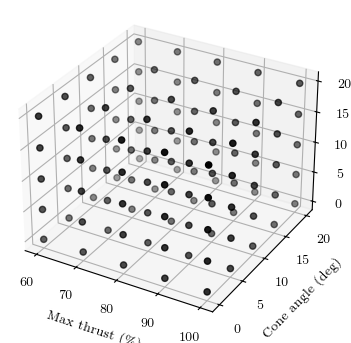

In [7]:
ax = plt.figure().add_subplot(projection="3d")
ax.scatter(df["max_thrust_percent"], df["cone"], df["tilt"])

ax.set_xlabel("Max thrust (%)")
ax.set_ylabel("Cone angle (deg)")
ax.set_zlabel("Tilt angle (deg)")

plt.show()

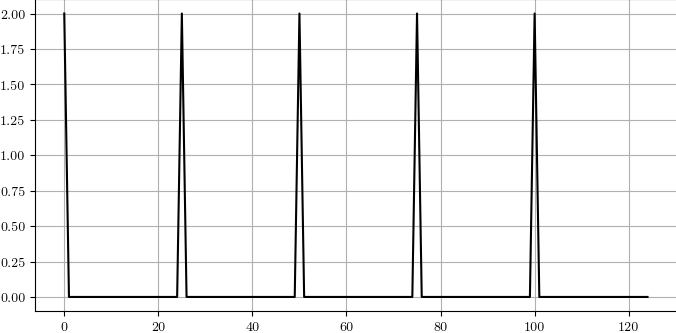

In [8]:
plt.plot(df["openfast_failed"])